# Exploration Preprocessing of stations data 

## Importing dependencises

Overview: This notebook covers the data cleaning, validation, and spatial preprocessing steps for the station dataset.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
from matplotlib.colors import LinearSegmentedColormap


In [25]:
# Set global seaborn style - clean background without grid
sns.set_style("white", {
    "axes.grid": False,           # Remove grid lines
    "axes.spines.left": True,     # Keep left spine
    "axes.spines.bottom": True,   # Keep bottom spine
    "axes.spines.top": False,     # Remove top spine
    "axes.spines.right": False,   # Remove right spine
    "axes.linewidth": 1.2,        # Slightly thicker axis lines
})

# Set inclusive and colorblind-friendly palette
# Using 'colorblind' palette which is accessible to colorblind users
sns.set_palette("colorblind")

## Data Exploration

In [26]:
df_stations=pd.read_csv("../stations.csv")
dim=df_stations.shape
print(dim)
print((df_stations).info())


(2932, 11)
<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 252.1 KB
None


In [27]:
df_stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


### missing values

In [28]:
def check_miss(df):  
    dim=df.shape
    n_miss = df.shape[0]-df.count()
    p_miss = (n_miss/dim[0])*100
    s_type = df.dtypes 
    n_values = df.nunique(dropna=True) 
    miss_df=pd.DataFrame()
    miss_df["n_missing"]=n_miss
    miss_df["p_missing"]=p_miss
    miss_df["feat_type"]=s_type
    miss_df["nu_unique"]=n_values
    return miss_df


In [29]:
display(check_miss(df_stations))

,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
name,0,0.000000,str,2855
app_number,0,0.000000,int64,2914
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
rack_locks,2932,100.000000,float64,0
lon,0,0.000000,float64,2912


we can see clearly that all the value of `rack_locks` column are missing making removing it the best choice for our cleaning process
`name`,`app_number` are dropped likewise, the columns were dropped as they provide no analytical value and are not used as a join key with any other dataset.

In [30]:
cleaned_df=df_stations.drop(["rack_locks","name","app_number"],axis=1)
display(check_miss(cleaned_df))


,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
lon,0,0.000000,float64,2912
lat,0,0.000000,float64,2911


### duplicated values


In [31]:
print("the number of duplicated values are :",cleaned_df.duplicated().sum())
print("the number of duplicated values are :",cleaned_df.duplicated().sum())


the number of duplicated values are : 0
the number of duplicated values are : 0


### Data Validation

in this section we will to check the validity of the data in case of odd values

In [32]:
print("number of false values in bike_racks", (cleaned_df.bike_racks<0).sum() ," \n values", cleaned_df.iloc[cleaned_df.bike_racks<0])
print("number of false values in special_racks", (cleaned_df.special_racks<0).sum()," \n values \n ", cleaned_df.iloc[cleaned_df.special_racks<0].to_string())
neg_points= cleaned_df.iloc[cleaned_df.special_racks<0]
neg_ids=neg_points.id


number of false values in bike_racks 0  
 values Empty DataFrame
Columns: [id, city_id, terminal_type, place_type, bike_racks, special_racks, lon, lat]
Index: []
number of false values in special_racks 32  
 values 
               id  city_id terminal_type  place_type  bike_racks  special_racks        lon        lat
455    19772006      643         7inch          14           6             -2  15.382405  46.380096
974    21257660      220         7inch          14           6             -2  16.043296  45.818237
982    60833931      220         7inch          14          10             -4  16.012638  45.796928
1202   16852569      327         7inch          14           2             -1  15.235639  44.104679
1311   40538270      415         7inch          14          10             -4  16.048545  45.718726
1326    3561904      429         7inch          14          20            -10  13.595022  45.214403
1329    3562085      429         7inch          14          10             -5  13.

we can see that all negative value have  the same place type and same terminal type

Negative values observed in special_racks share identical `place_type` and `terminal_type` attributes, suggesting a systematic data recording error.

To cross-examine these invalid entries, we evaluate status snapshots from `stations_status.csv` to compare observed historical maximum capacities against reported values.

In [33]:
stat_s=pd.read_csv("../stations_status.csv")

<Axes: xlabel='id'>

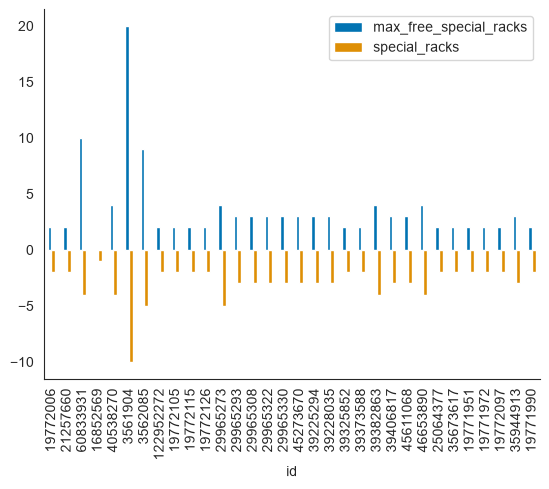

In [34]:

stat_s=stat_s.loc[stat_s.maintenance == False]
grouped_by_id=stat_s[["station_id","free_special_racks"]].groupby("station_id",as_index=False).max()
grouped_by_id.columns=["id","max_free_special_racks"]

join= grouped_by_id.merge(cleaned_df[["id","special_racks"]],on="id")
join.index=join.id
join[["max_free_special_racks","special_racks"]].loc[neg_ids].plot.bar(rot=90)

we can see that some values are not the same so the best choice is to remove the row with negativve values and keep them in seprated , givn the possibility that time time of count in stations.csv may differe than the max of stations.status.csv we choose not to consider in our anlaysis but impute them for our machine learning algorithms

In [35]:
removed_values=cleaned_df.iloc[cleaned_df.special_racks<0]
cleaned_df=cleaned_df.iloc[~cleaned_df.special_racks<0]

C:\Users\Lenovo PC\AppData\Local\Temp\ipykernel_11912\1929283515.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


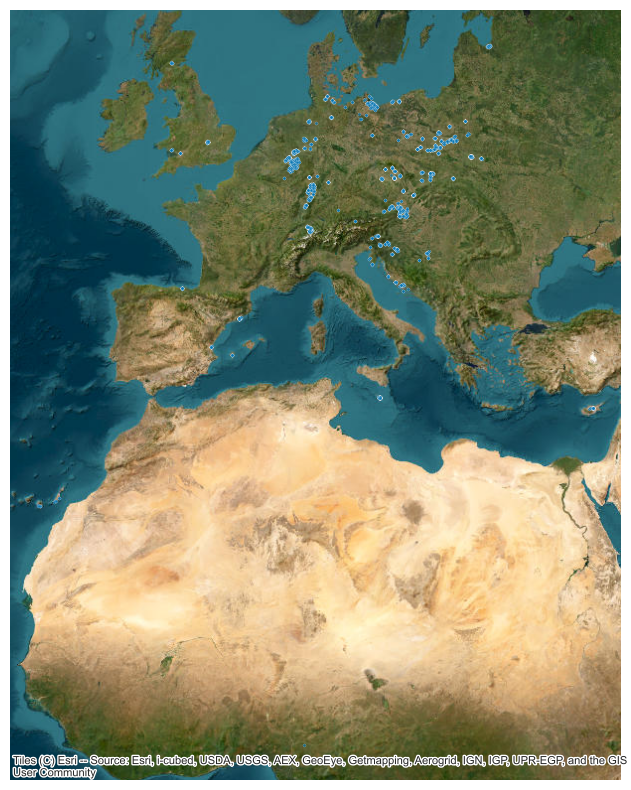

In [36]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,           
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

We can see some geospatial outliers Coordinates are evaluated against geographic bounding constraints for Europe ($\text{Latitude} \in [34^\circ, 71^\circ]$, $\text{Longitude} \in [-25^\circ, 60^\circ]$). points Outside these regions is either european small isolated territories  or utterly  falling outside european soil.

In [37]:
filter_lat=(~cleaned_df.lat.between(34,71))
filter_lon=(~cleaned_df.lon.between(-25,60))
filter_out=filter_lat | filter_lon
points_outside=cleaned_df.loc[filter_out]
points_outside

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
1658,18598248,638,7inch,14,4,0,-15.758277,27.824618
1659,18598681,638,7inch,14,4,0,-15.579987,27.762925
1660,18599537,638,7inch,14,6,0,-15.605667,27.742972
1661,18599596,638,7inch,14,6,0,-15.600083,27.740583
1662,18599750,638,7inch,14,4,0,-15.572444,27.756972
1663,18599772,638,7inch,14,4,0,-15.709750,27.781222
1664,18599901,638,7inch,14,6,0,-15.649778,27.782611
1665,18599488,675,7inch,14,4,0,-13.863219,28.390124
1666,18599628,675,7inch,14,6,0,-14.233111,28.150222
2486,205113328,858,free,0,0,0,7.801357,7.745476


C:\Users\Lenovo PC\AppData\Local\Temp\ipykernel_11912\656624631.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


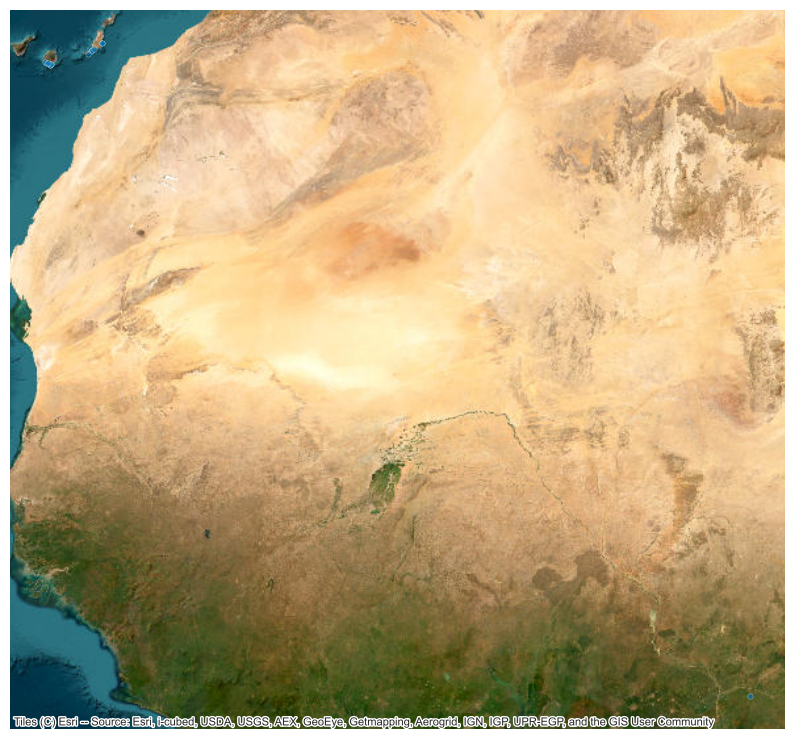

In [38]:
gdf = gpd.GeoDataFrame(
    points_outside,
    geometry=gpd.points_from_xy(points_outside.lon, points_outside.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=15,            # marker size (seaborn uses s, not markersize)
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

we can see clearly that these stations except the ones in canary islands are not in europe. 

In [39]:
canary_island_cityids=(638,675)
filter_cis=~((cleaned_df.city_id == canary_island_cityids[0]) | (cleaned_df.city_id == canary_island_cityids[1]))
new_filter = filter_cis & filter_out
cleaned_df.iloc[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.801357,7.745476


after checking the station id in bike_types we determined the correct values which  are 
7.803989,52.188201

In [40]:
cleaned_df.loc[new_filter,"lat"] = 52.188201
cleaned_df.loc[new_filter,"lon"] = 7.803989
cleaned_df[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.803989,52.188201


C:\Users\Lenovo PC\AppData\Local\Temp\ipykernel_11912\1107755531.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


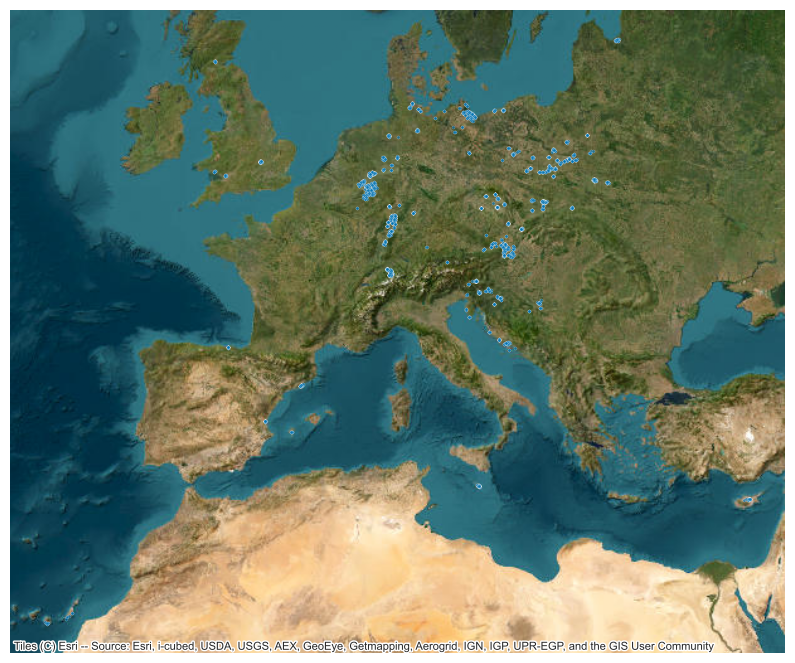

In [41]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,            # marker size (seaborn uses s, not markersize)
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

### Dealing with terminal type feature 

terminal_type feature  has more than 20% missing values with 10 unique values missing two types, (compared to the 12 expected types outlined in the dataset description in the challenge document).
for that missing entries are explicitly imputed with the string "Missing" to retain structural records without biasing distribution metrics.


<Axes: xlabel='terminal_type'>

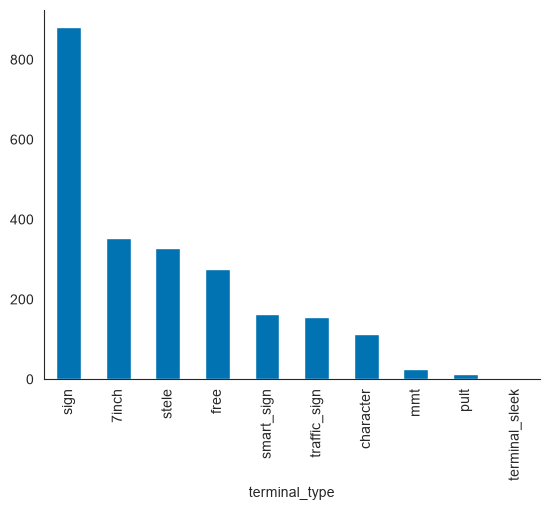

In [42]:
((cleaned_df.terminal_type.value_counts())).plot(kind="bar")


In [43]:
cleaned_df.terminal_type=cleaned_df.terminal_type.fillna("Missing")
cleaned_df

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
0,142186362,135,Missing,12,0,0,7.821669,51.677449
1,940986,176,Missing,0,6,0,13.868973,54.090538
2,93646685,176,stele,0,15,0,13.918970,54.073088
3,111365509,243,smart_sign,0,20,0,-3.936120,56.119272
4,405835,302,sign,0,6,0,14.481456,35.906836
...,...,...,...,...,...,...,...,...
2927,294352,128,Missing,0,11,0,24.156725,57.005195
2928,20729102,527,7inch,0,10,0,21.249210,52.121370
2929,9575430,530,Missing,0,9,0,6.440451,51.163646
2930,18599421,675,7inch,14,4,0,-13.864890,28.384953


# Statsiques analysis

In [44]:
matrix_correlation = cleaned_df.drop(["terminal_type","id","city_id"],axis=1).corr()
matrix_correlation

,place_type,bike_racks,special_racks,lon,lat
place_type,1.000000,-0.182787,0.083849,-0.354395,-0.057479
bike_racks,-0.182787,1.000000,0.012018,0.180057,0.167060
special_racks,0.083849,0.012018,1.000000,-0.007656,-0.006036
lon,-0.354395,0.180057,-0.007656,1.000000,-0.002151
lat,-0.057479,0.167060,-0.006036,-0.002151,1.000000


In [46]:
import folium
from folium.plugins import HeatMap
import pandas as pd

df_clean = cleaned_df.dropna(subset=['lat', 'lon'])

heat_data = df_clean[['lat', 'lon']].values.tolist()

center_lat = df_clean['lat'].mean()
center_lon = df_clean['lon'].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11, 
    tiles="OpenStreetMap"
)

HeatMap(
    data=heat_data,
    radius=15,
    blur=10,
    min_opacity=0.4
).add_to(m)

m.save('../assets/carte_robuste.html')
print(f"Carte générée avec {len(heat_data)} points. Ouvrez le fichier 'carte_robuste.html' dans votre navigateur.")


Carte générée avec 2900 points. Ouvrez le fichier 'carte_robuste.html' dans votre navigateur.


![img](../assets/Screenshot%202026-10-16%20172624.png)

<Axes: xlabel='bike_racks'>

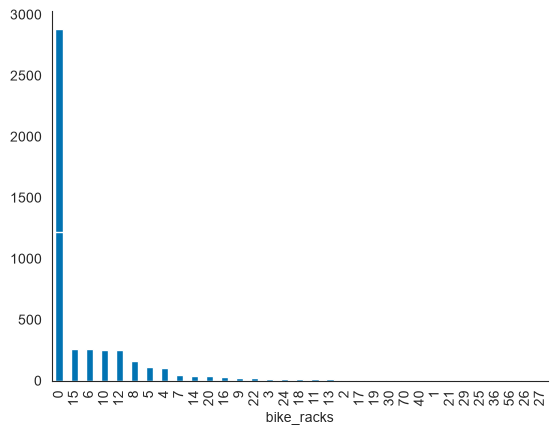

In [47]:
((cleaned_df.special_racks.value_counts())).plot.bar()
((cleaned_df.bike_racks.value_counts())).plot.bar()



<Axes: xlabel='terminal_type'>

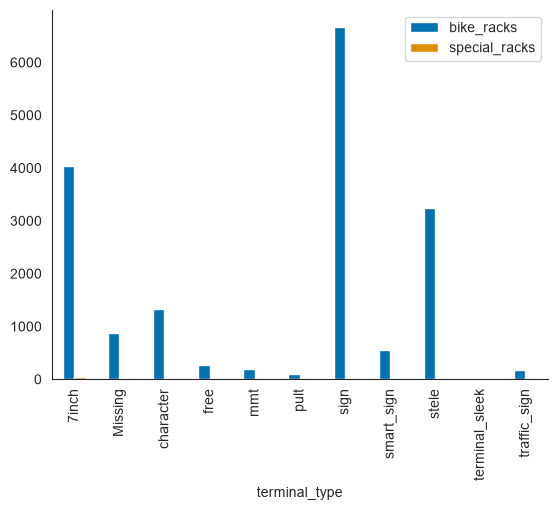

In [48]:

n_rack_pert=cleaned_df[["terminal_type","bike_racks","special_racks"]].groupby("terminal_type").sum()
n_rack_pert.plot.bar(rot=90)

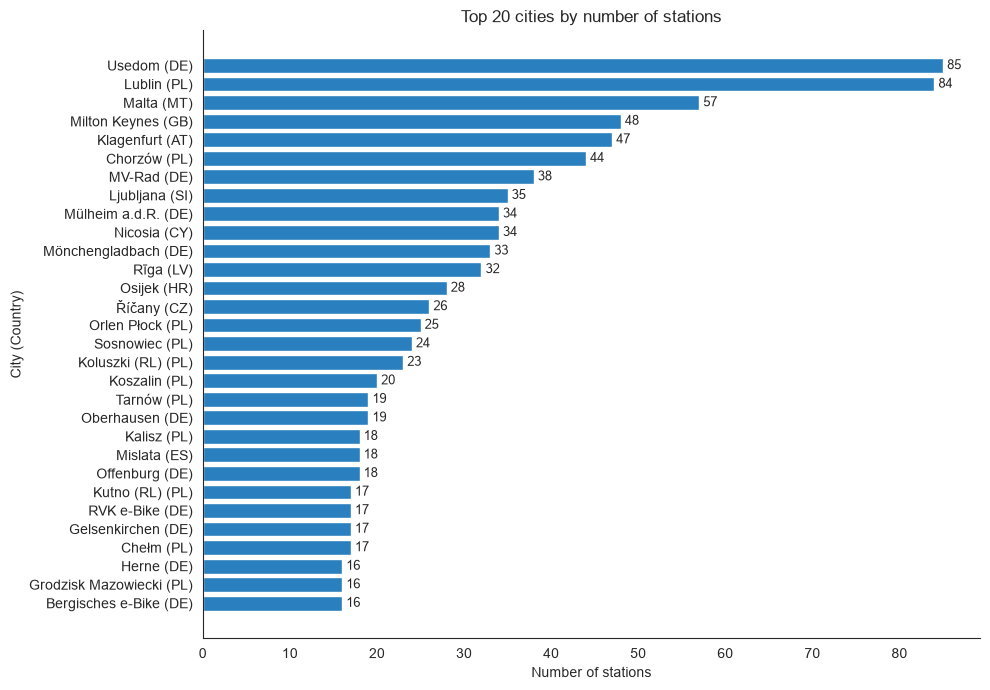

In [50]:
cities = pd.read_csv('../cities.csv')   # id, name, lat, lon, timezone, country, ...
info = cities.set_index('id')

df_st = cleaned_df[cleaned_df['bike_racks'] > 0]
top = df_st['city_id'].value_counts().head(30)      # top 20, already sorted

labels = [
    f"{info.at[i, 'name']} ({info.at[i, 'country']})" if i in info.index else str(i)
    for i in top.index
]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(labels, top.values, color='#2a7fbf')
ax.invert_yaxis()                                   # biggest city on top
ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title('Top 20 cities by number of stations')
ax.set_xlabel('Number of stations')
ax.set_ylabel('City (Country)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../assets/top20_cities.png', dpi=150)
plt.show()